# Lab 1: An Early-Warning System for Student Dropout (MLP)

**Hands-on lab · Multilayer perceptrons on real tabular data**

Every year, a share of students who start a programme never finish it. For the student it can mean lost time, money and confidence; for an institution it means a place that could have been filled, and a person it failed to keep. Most dropouts are not sudden. The signs often show up in the first semester: units not passed, fees falling behind, grades slipping. If a school could spot those signs early, a tutor could reach out while there is still time to help.

In this lab we build that early-warning system. We take records of real students, train a **multilayer perceptron (MLP)**, the simplest deep network, to estimate each student's risk of dropping out, and turn it into a small app a support team could use. Along the way we meet the questions that matter in any real deployment: *when* would we make the prediction, what should we compare against, how do we turn a score into a decision, and is the system fair to every group of students?

**What you'll see in this lab:**
- a real dataset of 4,424 students, and how to frame dropout prediction as a machine-learning task;
- why the *moment* of prediction decides which data we may use;
- preprocessing that an MLP needs (one-hot encoding and scaling), and what happens without it;
- an MLP built and trained in PyTorch with early stopping, compared honestly with simpler models;
- choosing a decision threshold, checking fairness across groups, and seeing what drives the risk;
- a working early-warning app.

**The data.** The *Predict Students' Dropout and Academic Success* dataset from the UCI Machine Learning Repository (licence CC BY 4.0). It describes students of a higher-education institution in Portugal: background at enrolment, socio-economic details, first- and second-semester academic results, and whether each student eventually graduated, was still enrolled, or dropped out. Grades are on Portugal's 0–20 scale. The records are anonymised.

### Running this lab

- **`TRAIN = True`** (the default) trains the model; it takes seconds on a laptop. Set it to `False` to load the model saved in `artifacts/` instead.
- **`LAUNCH_APP`** in the last cell opens the early-warning app inside the notebook. You can also run it on its own with `python app.py` in this folder.
- The dataset downloads into `data/` the first time.
- **Run the cells in order**, from top to bottom (Shift+Enter on each cell, or *Run All*). Later cells reuse what earlier cells created (for example `X_train`, `mlp` and `threshold`), so skipping a cell or running one out of order can fail or give different numbers.
- **Random seeds are fixed**, so a rerun should reproduce the numbers quoted in the text. On different hardware or library versions, the last decimal place may differ slightly.
- **What the notebook saves.** `data/data.csv` (the dataset), and in `artifacts/` the four files the app needs: `mlp.pt` (the trained weights), `preprocessor.joblib` (the fitted encoding and scaling), `preprocessor_columns.json` (the column lists and the chosen threshold) and `example_student.json` (a student whose record fills the app's default values).
- **Try it yourself** boxes are optional experiments. Change one value, rerun from that cell onwards, and compare with the text. Then change it back, so that later sections and the app match the explanations.
- You need Python with PyTorch, scikit-learn, pandas and matplotlib; the app also uses `joblib` and `gradio`. The first run needs an internet connection to download the data.

### Roadmap

- **Section 1 – The Problem and the Data:** load the table, look at it, and define the yes/no outcome *dropout*.
- **Section 2 – When Would We Make the Prediction?** Decide which columns may be used (no second-semester data).
- **Section 3 – Splitting and Preparing the Data:** training/validation/test split, one-hot encoding and scaling.
- **Section 4 – Baselines First:** what guessing and logistic regression score, the bar to beat.
- **Section 5 – The MLP:** define, train (with early stopping) and score the network; check stability over seeds.
- **Section 6 – Why Preprocessing Matters:** the same MLP on raw columns.
- **Section 7 – Is a Neural Network the Right Tool?** Gradient-boosted trees, and the leakage-in-time temptation.
- **Section 8 – From Scores to Decisions:** choose a threshold, count flags, catches and false alarms.
- **Section 9 – Is It Fair?** The same numbers per gender, scholarship and age group.
- **Section 10 – What Drives the Risk?** Which columns the model relies on most.
- **Section 11 – The Application:** save the model, ask "what if" questions, rank students, and launch the app.
- **What We Learned**, followed by a short glossary of key terms.

The first code cell loads the libraries, sets the `TRAIN` flag, fixes the random seeds (so that results are repeatable), and chooses the device: a GPU if one is available, otherwise the CPU. It prints the PyTorch version and the device.

In [27]:
# Standard library: files, in-memory bytes, JSON, timing, zip archives and downloading.
import os, io, json, time, zipfile, urllib.request
# Numerical arrays and tables.
import numpy as np
import pandas as pd
# PyTorch: tensors, and the building blocks for neural networks (layers, losses).
import torch
import torch.nn as nn
# Plotting.
import matplotlib.pyplot as plt
# scikit-learn: splitting data, preprocessing, two comparison models and the evaluation metrics.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

TRAIN = True                      # False: load the saved model from artifacts/ instead of training
# Fix the random seeds so that every run of the notebook gives the same split, weights and numbers.
torch.manual_seed(0)
np.random.seed(0)
# Use a GPU if there is one; this small model trains in seconds on a CPU anyway.
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1 | device: cpu


## 1. The Problem and the Data

The dataset is a single table, one row per student:

The next cell downloads it (only the first time), loads it with pandas, and prints its **shape**, (number of rows, number of columns), followed by how many students had each outcome in the `Target` column.

In [28]:
# Official download link for the UCI "Predict Students' Dropout and Academic Success" dataset (a zip file).
URL = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
os.makedirs("data", exist_ok=True)
# Download only once: if data/data.csv already exists, we skip the network entirely.
if not os.path.exists("data/data.csv"):
    # Read the zip into memory and pull out just the one CSV file we need.
    with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL).read())) as z:
        z.extract("data.csv", "data")
# The file uses semicolons, not commas, between values.
df = pd.read_csv("data/data.csv", sep=";")
df.columns = [c.strip() for c in df.columns]                    # one column name has a stray tab
# Shape is (rows, columns) = (students, columns); then count each outcome in the Target column.
print(df.shape)
print(df["Target"].value_counts())

(4424, 37)
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [30]:
df.head()    # the first five students: a quick look at the raw table

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [31]:
df.info()    # every column: its name, how many values are filled in, and its type

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

There are 4,424 students and 37 columns: 36 descriptions of each student, plus `Target`, the outcome. 2209 graduated, 1421 dropped out, and 794 were still enrolled when the data was collected. A few columns for the first three students:

In [32]:
# Show the first 3 students and a hand-picked set of 11 columns (by position), so the table fits on screen.
df.iloc[:3, [0, 3, 12, 15, 16, 17, 18, 19, 23, 24, 36]]

,Marital status,Course,Admission grade,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Target
0,1,171,127.3,0,1,1,0,20,0,0,Dropout
1,1,9254,142.5,0,0,1,0,19,6,6,Graduate
2,1,9070,124.8,0,0,1,0,19,0,0,Dropout


Notice that many columns are **numeric codes**, not quantities. `Course` 171 or 9254 is the identity of a programme, not an amount; the same goes for marital status, nationality, parents' occupations and so on. We'll have to treat those differently from real quantities like `Admission grade` or `Age at enrollment`.

For an early-warning system, the question is simply: *will this student drop out?* We combine "graduated" and "still enrolled" into "did not drop out".

The next cell creates this new 0/1 column, `dropout`. It is our **label** (also called the *target*): the answer the model must learn to predict from the other columns. The average of a 0/1 column is simply the share of 1s.

In [33]:
# Turn the three-way outcome into a yes/no label: this is the thing the model will learn to predict.
df["dropout"] = (df["Target"] == "Dropout").astype(int)        # 1 = dropped out, 0 = graduated or still enrolled
# The mean of a 0/1 column is the share of 1s, i.e. the dropout rate (the "base rate").
print(f"dropout rate: {df['dropout'].mean():.1%} of {len(df):,} students")

dropout rate: 32.1% of 4,424 students


32.1% of students dropped out: roughly one in three. That's the **base rate**: a system that flagged students at random would be right about one time in three.

## 2. When Would We Make the Prediction?

This is the most important design decision in the lab, and it isn't about models. The table includes *second-semester* results. If our tutors want to intervene during the first year, those results don't exist yet at the moment we need the warning. Using them would be **leakage in time**: the model would look brilliant in testing and be impossible to use.

So we define the prediction moment as **the end of the first semester**: we may use everything known at enrolment plus first-semester results, but nothing later.

The next cell sorts the columns into lists: the second-semester columns (`second_sem`), the coded categories (`nominal`, written by hand because nothing in the file says which numbers are codes), all numeric columns (`numeric_all`) and the numeric columns we may use at the end of the first semester (`numeric_early`).

In [34]:
# Every column about the 2nd semester. At our prediction moment (end of semester 1) these don't exist yet.
second_sem = [c for c in df.columns if "2nd sem" in c]
second_sem

['Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (evaluations)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Curricular units 2nd sem (without evaluations)']

In [35]:
# Columns whose numbers are codes (labels), not amounts. They will be one-hot encoded, not scaled.
nominal = ["Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
           "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
nominal

['Marital status',
 'Application mode',
 'Course',
 'Previous qualification',
 'Nacionality',
 "Mother's qualification",
 "Father's qualification",
 "Mother's occupation",
 "Father's occupation"]

In [36]:
# Everything else except the outcome columns is a real quantity (or a 0/1 flag).
numeric_all = [c for c in df.columns if c not in nominal + ["Target", "dropout"]]
numeric_all

['Application order',
 'Daytime/evening attendance',
 'Previous qualification (grade)',
 'Admission grade',
 'Displaced',
 'Educational special needs',
 'Debtor',
 'Tuition fees up to date',
 'Gender',
 'Scholarship holder',
 'Age at enrollment',
 'International',
 'Curricular units 1st sem (credited)',
 'Curricular units 1st sem (enrolled)',
 'Curricular units 1st sem (evaluations)',
 'Curricular units 1st sem (approved)',
 'Curricular units 1st sem (grade)',
 'Curricular units 1st sem (without evaluations)',
 'Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (evaluations)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Curricular units 2nd sem (without evaluations)',
 'Unemployment rate',
 'Inflation rate',
 'GDP']

In [37]:
# The numeric columns we are allowed to use: all of them minus the 2nd-semester ones (avoids leakage in time).
numeric_early = [c for c in numeric_all if c not in second_sem]
numeric_early

['Application order',
 'Daytime/evening attendance',
 'Previous qualification (grade)',
 'Admission grade',
 'Displaced',
 'Educational special needs',
 'Debtor',
 'Tuition fees up to date',
 'Gender',
 'Scholarship holder',
 'Age at enrollment',
 'International',
 'Curricular units 1st sem (credited)',
 'Curricular units 1st sem (enrolled)',
 'Curricular units 1st sem (evaluations)',
 'Curricular units 1st sem (approved)',
 'Curricular units 1st sem (grade)',
 'Curricular units 1st sem (without evaluations)',
 'Unemployment rate',
 'Inflation rate',
 'GDP']

In [38]:
print(f"{len(nominal)} coded categories | {len(numeric_all)} numeric columns, of which {len(second_sem)} describe the 2nd semester")

9 coded categories | 27 numeric columns, of which 6 describe the 2nd semester


Of the 36 descriptions, 9 are coded categories, and 27 are numeric, of which 6 describe the second semester. We drop those 6. Section 7 shows what we'd be tempted to report if we kept them.

## 3. Splitting and Preparing the Data

We split students into **training** (60%), **validation** (20%, for choices such as when to stop training and where to put the threshold) and **test** (20%, used only to report results). The split is **stratified**, so each part keeps the same dropout rate:

(Stratified means the split is done separately within dropouts and non-dropouts, so each part gets its fair share of both.)

In [8]:
# First split: 60% training, 40% "rest". stratify keeps the dropout rate the same in both parts.
train_df, rest = train_test_split(df, test_size=0.4, stratify=df["dropout"], random_state=0)
# Second split: cut the rest in half, giving 20% validation (for choices) and 20% test (for the final report).
val_df, test_df = train_test_split(rest, test_size=0.5, stratify=rest["dropout"], random_state=0)
# Check the sizes and that each part has (almost) the same dropout rate.
for name, d in (("train", train_df), ("validation", val_df), ("test", test_df)):
    print(f"{name:<10} {len(d):>5} students | dropout rate {d['dropout'].mean():.1%}")

train       2654 students | dropout rate 32.1%
validation   885 students | dropout rate 32.2%
test         885 students | dropout rate 32.1%


**What to notice:** the three dropout rates are almost identical, which is exactly what stratifying is for. Validation and test are the same size, and neither is used for training.

Neural networks need numbers in a sensible form, so preprocessing does two things:
- **One-hot encoding** turns each coded category into separate yes/no columns (one per course, one per nationality, and so on), so the model never treats code 9254 as "bigger" than code 171. Rare categories (fewer than 20 students) are grouped together.
- **Standard scaling** gives every numeric column mean 0 and standard deviation 1, so that ages, grades and admission scores, which come in very different ranges, arrive on comparable scales.

The preprocessor is **fitted on the training students only** and then applied to the others, so no information from validation or test leaks into it.

Why does that matter? Scaling uses a mean and a standard deviation. If those were computed on all students, a little information about the test students would be built into the inputs, and the test score would be slightly too optimistic.

The next cell defines `make_preprocessor` (we reuse it in Section 7 with a different list of columns), fits it on the training students, and turns all three parts into arrays of numbers: `X_...` holds the inputs, one row per student, and `y_...` the 0/1 labels.

In [40]:
def make_preprocessor(numeric):
    """Build (but do not fit) the preprocessing step that turns a table of students into model inputs.

    Input:  numeric - list of numeric column names to scale (the coded columns in `nominal` are always included).
    Output: an unfitted sklearn ColumnTransformer. After .fit(...), .transform(df) returns a
            (n_students, n_features) float array: one-hot columns for the codes, followed by the scaled numbers.
    Rare categories (fewer than 20 training students) are merged into one "infrequent" column, and
    categories never seen in training are mapped there too instead of causing an error.
    """
    return ColumnTransformer([
        # Codes -> one yes/no column per category, so code 9254 is never treated as "bigger" than 171.
        ("categories", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), nominal),
        # Quantities -> mean 0, standard deviation 1, so no column dominates just because its numbers are large.
        ("numbers", StandardScaler(), numeric)])

In [42]:
# Fit = learn the categories, means and standard deviations. We use ONLY training students,
# so nothing about validation or test students leaks into the inputs.
pre = make_preprocessor(numeric_early).fit(train_df)                  # fitted on training students only
# Apply the same fitted transformation to all three parts. float32 is the number type PyTorch expects.
X_train, X_val, X_test = (pre.transform(d).astype(np.float32) for d in (train_df, val_df, test_df))
# Labels as plain 0/1 NumPy arrays, shape (n_students,).
y_train, y_val, y_test = (d["dropout"].to_numpy() for d in (train_df, val_df, test_df))
# X_train has shape (n_training_students, n_features); the second number is the network's input size.
print("inputs per student after encoding:", X_train.shape[1])

inputs per student after encoding: 109


After encoding, each student is described by 109 numbers. That is more numbers than original columns, because every coded column has become several yes/no columns, one per category.

> **Try it yourself (optional).** In `make_preprocessor`, make `min_frequency` much smaller or much larger, then rerun from that cell to the end of Section 5. Look at the *inputs per student* line: how many columns does one-hot encoding create now? Does the MLP's validation ROC-AUC change noticeably, or barely at all?

## 4. Baselines First

Before building a neural network, we measure what simpler approaches achieve. Two numbers summarise how well a model *ranks* students by risk:
- **ROC-AUC:** the chance that a randomly chosen dropout gets a higher risk score than a randomly chosen non-dropout. 0.5 is guessing, 1.0 is perfect.
- **Average precision:** how precise the flags are, averaged over all thresholds. Guessing scores the base rate.

(**Precision** is the share of flagged students who really drop out; we come back to it, and to its partner *recall*, in Section 8.)

The next cell defines a small helper, `score`, that computes both measures on validation and test for any model and stores them in `results`. It then scores two baselines: a "model" that gives every student the same risk (the training dropout rate), and **logistic regression**, a classic linear model that adds up weighted inputs and squashes the total into a probability.

In [45]:
# Collect every model's scores here, so later cells can look them up by name.
results = {}
def score(name, p_val, p_test):
    """Evaluate one model's risk scores on validation and test, store them in `results`, and print a line.

    Inputs: name   - label for the model (used as the key in `results`);
            p_val  - predicted dropout probabilities for the validation students, shape (n_val,);
            p_test - the same for the test students, shape (n_test,).
    Uses the global labels y_val and y_test. Returns nothing.
    ROC-AUC and average precision only care about how students are *ranked*, so no threshold is needed yet.
    """
    results[name] = {"val_auc": roc_auc_score(y_val, p_val), "test_auc": roc_auc_score(y_test, p_test),
                     "val_ap": average_precision_score(y_val, p_val), "test_ap": average_precision_score(y_test, p_test)}
    r = results[name]
    print(f"{name:<32} ROC-AUC val {r['val_auc']:.3f} test {r['test_auc']:.3f} | average precision val {r['val_ap']:.3f} test {r['test_ap']:.3f}")

In [46]:
# Baseline 1: give every student the same risk (the training dropout rate). This is what "no skill" scores.
score("always the base rate", np.full(len(y_val), y_train.mean()), np.full(len(y_test), y_train.mean()))

always the base rate             ROC-AUC val 0.500 test 0.500 | average precision val 0.322 test 0.321


In [48]:
# Baseline 2: logistic regression, a single linear layer plus sigmoid. max_iter is high so it fully converges.
logreg = LogisticRegression(max_iter=5000, C=1.0).fit(X_train, y_train)
# predict_proba returns two columns (P(no dropout), P(dropout)); [:, 1] keeps the dropout probability.
score("logistic regression", logreg.predict_proba(X_val)[:, 1], logreg.predict_proba(X_test)[:, 1])

logistic regression              ROC-AUC val 0.887 test 0.921 | average precision val 0.853 test 0.880


Guessing scores exactly 0.500 ROC-AUC and an average precision of 0.321, the base rate. Plain **logistic regression**, a single linear layer, already reaches 0.921 ROC-AUC on test. That's the bar our MLP has to clear.

**How to read this output:** each line shows ROC-AUC and average precision on the validation students and on the test students. Validation and test differ a little simply because they are different students; we use validation numbers to make choices and test numbers only to report.

## 5. The MLP

An **MLP** stacks linear layers with non-linear activations between them, so it can learn interactions between inputs that a single linear layer can't. Ours is small: 109 inputs → 32 → 16 → 1 risk score, with ReLU activations and **dropout** (randomly silencing 20% of units during training) to reduce overfitting.

Training uses the loop from Module 2, with two additions:
- **AdamW** with a little weight decay;
- **early stopping:** after each epoch we check the loss on the validation students, keep the best version, and stop once it has failed to improve for 15 epochs.

A few terms used in the next cell:
- **ReLU** (rectified linear unit) is the non-linear activation: it passes positive values through and turns negative values into 0. Without it, stacked linear layers would collapse into a single linear layer.
- An **epoch** is one full pass over the training students. Within an epoch, the students are shuffled and processed in **mini-batches** (small groups); the weights are updated after each mini-batch.
- The network's raw output is a **logit**, any real number. The **sigmoid** function turns it into a probability between 0 and 1.
- The loss is **binary cross-entropy**: small when the predicted probability is close to the true 0/1 label, large when it is confidently wrong. `BCEWithLogitsLoss` applies the sigmoid and this loss together, which is numerically safer.
- **Weight decay** gently pulls the weights towards zero at every step, another guard against overfitting.

The cell only *defines* the model and two functions: `train_mlp` (training with early stopping) and `mlp_proba` (turning a trained model's logits into probabilities). It prints nothing. The cell after it does the training, or loads the saved model when `TRAIN = False`, and scores the MLP exactly like the baselines.

In [60]:
class DropoutMLP(nn.Module):
    """A small multilayer perceptron: inputs -> 32 -> 16 -> 1 risk score.

    n_in   - number of input features per student (109 after our preprocessing).
    p_drop - dropout probability: the share of hidden units randomly switched off during training,
             which stops the network relying too heavily on any single unit (less overfitting).
    The output is a raw score (a "logit"), not a probability; apply torch.sigmoid to get a 0-1 risk.
    """
    def __init__(self, n_in, p_drop=0.2):
        """Create the layers. Each Linear layer is followed by ReLU (non-linearity) and Dropout, except the last."""
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 32), nn.ReLU(), nn.Dropout(p_drop),     # hidden layer 1: 32 units
            nn.Linear(32, 16), nn.ReLU(), nn.Dropout(p_drop),       # hidden layer 2: 16 units
            nn.Linear(16, 1))                                       # output: one number per student
    def forward(self, x):                                  # x: (batch, n_in)
        """Map a (batch, n_in) float32 tensor to a (batch,) tensor of logits (one per student)."""
        # The last layer gives shape (batch, 1); squeeze(-1) drops the size-1 axis to match the labels' shape.
        return self.net(x).squeeze(-1)                     # (batch,) logits

In [61]:
def train_mlp(X_tr, y_tr, X_v, y_v, seed=0, max_epochs=200, patience=15):
    """Train a DropoutMLP with mini-batches and early stopping, and return the best version.

    Inputs:  X_tr, X_v - (n_students, n_features) float32 NumPy arrays for training and validation;
             y_tr, y_v - (n_students,) 0/1 label arrays;
             seed      - random seed for the starting weights and the batch order (for reproducible runs);
             max_epochs - upper limit on passes over the training data;
             patience  - stop after this many epochs in a row without a better validation loss.
    Outputs: (model, history). model holds the weights from the epoch with the lowest validation loss;
             history is a list of (training loss, validation loss) pairs, one per epoch that ran.
    """
    torch.manual_seed(seed)                                 # same seed -> same starting weights and dropout masks
    model = DropoutMLP(X_tr.shape[1]).to(device)
    # AdamW: the Adam optimiser with weight decay, a gentle pull of the weights towards zero
    # (another guard against overfitting).
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    # Binary cross-entropy that takes raw logits; it applies the sigmoid internally in a numerically stable way.
    loss_fn = nn.BCEWithLogitsLoss()
    # Move the data to tensors on the chosen device. Labels must be float for BCE loss.
    Xt, yt = torch.tensor(X_tr, device=device), torch.tensor(y_tr, dtype=torch.float32, device=device)
    Xv, yv = torch.tensor(X_v, device=device), torch.tensor(y_v, dtype=torch.float32, device=device)
    g = torch.Generator().manual_seed(seed)                 # own random generator: reproducible batch order
    # best = lowest validation loss so far; best_state = a copy of the weights at that point;
    # wait = epochs since the last improvement; history = losses per epoch (for the plot).
    best, best_state, wait, history = float("inf"), None, 0, []
    for epoch in range(max_epochs):
        model.train()                                       # training mode: dropout is active
        # Shuffle the student indices, then cut them into mini-batches of 64.
        for b in torch.randperm(len(Xt), generator=g).split(64):
            # The usual three steps: clear old gradients, compute loss and gradients, update the weights.
            opt.zero_grad(); loss_fn(model(Xt[b]), yt[b]).backward(); opt.step()
        model.eval()                                        # evaluation mode: dropout switched off
        with torch.no_grad():                               # no gradients needed just to measure the loss
            tr_loss, v_loss = loss_fn(model(Xt), yt).item(), loss_fn(model(Xv), yv).item()
        history.append((tr_loss, v_loss))
        # Count it as an improvement only if validation loss falls by more than a tiny margin (1e-4).
        if v_loss < best - 1e-4:                            # early stopping on validation loss
            # Save a *copy* (clone) of the weights; otherwise later training would overwrite them.
            best, best_state, wait = v_loss, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:                            # no progress for `patience` epochs: stop training
                break
    # Roll back to the best epoch's weights, not the last epoch's (which had started to overfit).
    model.load_state_dict(best_state)
    return model, history

In [62]:
def mlp_proba(model, X):
    """Return dropout probabilities for a (n_students, n_features) float32 array, as a (n_students,) NumPy array."""
    model.eval()                                            # make sure dropout is off for predictions
    with torch.no_grad():
        # logits -> sigmoid -> probabilities between 0 and 1; .cpu().numpy() brings them back to NumPy.
        return torch.sigmoid(model(torch.tensor(X, device=device))).cpu().numpy()

In [63]:
os.makedirs("artifacts", exist_ok=True)                     # the app will load the trained model from here
if TRAIN:
    t0 = time.perf_counter()                                # start a timer
    mlp, history = train_mlp(X_train, y_train, X_val, y_val, seed=0)
    # Best epoch = the epoch with the lowest validation loss (+1 because epochs are counted from 1).
    print(f"trained for {len(history)} epochs in {time.perf_counter() - t0:.1f} s | best epoch {int(np.argmin([v for _, v in history])) + 1}")
    torch.save(mlp.state_dict(), "artifacts/mlp.pt")       # save only the weights; the class above rebuilds the model
else:
    # Rebuild an empty model of the same shape, then load the saved weights into it.
    mlp = DropoutMLP(X_train.shape[1]).to(device)
    mlp.load_state_dict(torch.load("artifacts/mlp.pt")); history = None
    print("loaded artifacts/mlp.pt")
# Score the MLP exactly as we scored the baselines, so the numbers are directly comparable.
score("MLP (PyTorch)", mlp_proba(mlp, X_val), mlp_proba(mlp, X_test))

trained for 26 epochs in 0.3 s | best epoch 12
MLP (PyTorch)                    ROC-AUC val 0.893 test 0.916 | average precision val 0.855 test 0.875


Training takes under a second on a CPU. The saved run completed 26 epochs and kept the weights from epoch 12, where validation loss was lowest. On test, the MLP reaches 0.916 ROC-AUC and 0.875 average precision. The loss curves show why early stopping matters:

(Training time, the stopping epoch and scores can vary with hardware and library versions. These values describe the saved reference run.)

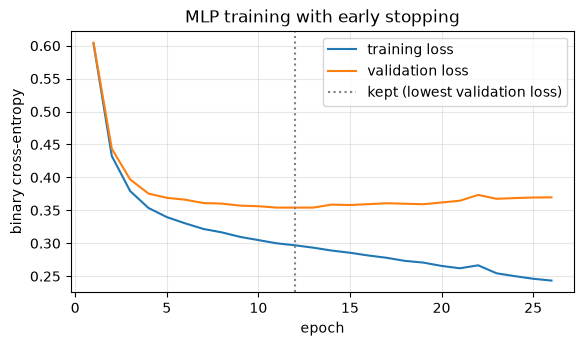

In [64]:
# The loss history only exists if we trained in this session (TRAIN = True).
if history:
    tr, va = zip(*history)                                  # split the (train, val) pairs into two sequences
    plt.figure(figsize=(6.5, 3.4))
    ep = range(1, len(tr) + 1)                              # epoch numbers 1, 2, 3, ...
    plt.plot(ep, tr, label="training loss"); plt.plot(ep, va, label="validation loss")
    # Dotted line at the epoch whose weights we kept.
    plt.axvline(int(np.argmin(va)) + 1, color="grey", ls=":", label="kept (lowest validation loss)")
    plt.xlabel("epoch"); plt.ylabel("binary cross-entropy"); plt.legend(); plt.grid(alpha=0.3)
    plt.title("MLP training with early stopping"); plt.show()

Training loss keeps falling, because the network keeps getting better at the students it has memorised. But validation loss bottoms out early and then rises: **overfitting**. Early stopping keeps the version from the dotted line.

Training involves randomness: the starting weights, the dropout masks and the order of the mini-batches all depend on the **random seed**. A different seed gives a slightly different model.

Is that result luck? We train five more times from different random starting weights:

In [65]:
# Retrain with different seeds to see how much the result depends on the random starting weights.
seed_aucs = []
for seed in range(1, 6):                                  # five more training runs, different random starts
    m, _ = train_mlp(X_train, y_train, X_val, y_val, seed=seed)
    seed_aucs.append(roc_auc_score(y_val, mlp_proba(m, X_val)))
# A narrow spread means the result is reliable, not a lucky draw.
print("validation ROC-AUC over 5 more seeds:", [round(a, 3) for a in seed_aucs], f"| spread {min(seed_aucs):.3f}-{max(seed_aucs):.3f}")

validation ROC-AUC over 5 more seeds: [0.895, 0.89, 0.889, 0.894, 0.892] | spread 0.889-0.895


Validation ROC-AUC stays between 0.889 and 0.895. The result is stable, not a lucky run.

> **Try it yourself (optional).** In `DropoutMLP`, double both hidden sizes, or remove the second hidden layer, or change `p_drop`. Rerun from that cell to here. Look for: does the best epoch come earlier or later? Does the validation ROC-AUC move outside the range over seeds above? Does the MLP get clearly ahead of logistic regression? (Undo the change before Section 11: `app.py` contains its own copy of the original architecture and could not load different weights.)

> **Try it yourself (optional).** In `train_mlp`, set `patience` to 1, or make it equal to `max_epochs`. Look at the number of epochs trained, the gap between the two curves on the plot, and the scores. Remember that the function always rolls back to the best epoch's weights, so the main effect of a very large patience is wasted training time.

## 6. Why Preprocessing Matters for an MLP

What if we skip the encoding and scaling and feed the raw columns straight in?

The next cell trains the same network with the same settings and seed on the raw columns, and prints its validation ROC-AUC next to the one we got with preprocessing. It also prints the largest values found in the raw columns.

In [66]:
# An experiment: skip the preprocessor and feed the raw columns (codes as numbers, nothing scaled).
X_train_raw = train_df[nominal + numeric_early].to_numpy(np.float32)    # no one-hot, no scaling
X_val_raw = val_df[nominal + numeric_early].to_numpy(np.float32)
# Same network, same training settings, same seed: the only difference is the input preparation.
m_raw, h_raw = train_mlp(X_train_raw, y_train, X_val_raw, y_val, seed=0)
print(f"MLP on raw, unscaled columns: validation ROC-AUC {roc_auc_score(y_val, mlp_proba(m_raw, X_val_raw)):.3f} "
      f"(vs {results['MLP (PyTorch)']['val_auc']:.3f} with encoding and scaling)")
# Show the three columns with the largest raw values, to see why scale matters.
print("largest raw column values:", train_df[nominal + numeric_early].max().sort_values(ascending=False).head(3).to_dict())

MLP on raw, unscaled columns: validation ROC-AUC 0.517 (vs 0.893 with encoding and scaling)
largest raw column values: {'Course': 9991.0, "Father's occupation": 195.0, "Mother's occupation": 194.0}


Without encoding and scaling, the same architecture reaches only **0.517 validation ROC-AUC**, close to guessing, compared with **0.893** after preprocessing. Raw columns have very different scales (`Course` codes reach 9991, while flags are 0 or 1), and treating category codes as quantities imposes a misleading numeric ordering. This experiment changes encoding and scaling together, so it does not isolate their individual effects.


## 7. Is a Neural Network the Right Tool Here?

For tables of mixed features like this, **gradient-boosted trees** are the usual industry favourite (you met them in Module 4's bake-off). They build many small decision trees one after another, each one correcting the mistakes of those before it. Let's compare:

In [67]:
# Gradient-boosted trees: many small decision trees, each correcting the previous ones' errors.
# Trees don't need scaling, but we reuse the same inputs so the comparison is fair.
gbt = HistGradientBoostingClassifier(random_state=0).fit(X_train, y_train)
score("gradient-boosted trees", gbt.predict_proba(X_val)[:, 1], gbt.predict_proba(X_test)[:, 1])

gradient-boosted trees           ROC-AUC val 0.880 test 0.900 | average precision val 0.842 test 0.852


Gradient-boosted trees reach 0.900 ROC-AUC on test, slightly below logistic regression (0.921) and the MLP (0.916). On this dataset, the three are close, and the simplest model is as good as any. That's a common and honest result for tabular data: a neural network is a reasonable choice, but not automatically the best one. Choose based on measurements, and on what else matters, such as explainability and ease of maintenance.

And here's the leakage-in-time temptation from Section 2. If we add the second-semester columns back:

The next cell builds a second preprocessor that includes the second-semester columns, trains the same MLP on it, and scores it.

In [68]:
# The leakage-in-time temptation: a preprocessor that also includes the 2nd-semester columns.
pre_all = make_preprocessor(numeric_all).fit(train_df)
# Transform all three parts with it (np.asarray makes sure we get a plain float32 array).
Xa_tr, Xa_val, Xa_te = (np.asarray(pre_all.transform(d), dtype=np.float32) for d in (train_df, val_df, test_df))
m_all, _ = train_mlp(Xa_tr, y_train, Xa_val, y_val, seed=0)
# This score looks better but could never be achieved at the end of the first semester.
score("MLP, 2nd semester included", mlp_proba(m_all, Xa_val), mlp_proba(m_all, Xa_te))

MLP, 2nd semester included       ROC-AUC val 0.908 test 0.934 | average precision val 0.879 test 0.901


Test ROC-AUC jumps to 0.934. It looks like an improvement, but it isn't usable: at the end of the first semester, those columns are blank. Reporting this number to a school would promise accuracy the system can never deliver. Always match the features to the moment of prediction.

## 8. From Scores to Decisions: Choosing a Threshold

The model outputs a risk between 0 and 1, but a support team needs a yes/no: *contact this student or not*. The **threshold** sets that line, and it's a trade-off. A lower threshold catches more future dropouts (higher **recall**) but raises more false alarms (lower **precision**).

- **Recall** = dropouts flagged ÷ all students who dropped out. *Of the students who needed help, how many did we reach?*
- **Precision** = dropouts flagged ÷ all students flagged. *Of the students we contacted, how many really needed it?*
- A **false alarm** (false positive) is a flagged student who would not have dropped out; a **missed dropout** (false negative) is a student who dropped out without being flagged.

Suppose the support team says: *we want to reach at least 4 in 5 students who would drop out.* We choose the threshold on the validation students to meet that, then check it once on test:

Why validation, not test? Choosing the threshold is a decision, just like choosing when to stop training. If we tuned it on the test students, the test result would no longer be an honest preview of new students. The cell computes precision and recall for every possible threshold on validation, keeps the highest threshold that still reaches the target recall (a higher threshold means fewer false alarms), and then applies it once to the test students.

In [18]:
# Risk scores from our MLP for validation (to choose the threshold) and test (to check it once).
p_val, p_test = mlp_proba(mlp, X_val), mlp_proba(mlp, X_test)
# For every possible threshold on the validation students: the precision and recall it would give.
# rec is in decreasing order as the threshold rises; rec and prec have one more entry than thr.
prec, rec, thr = precision_recall_curve(y_val, p_val)
target_recall = 0.80                                           # the support team wants to reach 4 in 5 future dropouts
# Among thresholds that still reach the target recall, take the last (highest) one: that keeps false alarms lowest.
i = np.where(rec[:-1] >= target_recall)[0][-1]                 # the highest threshold that still reaches it
threshold = float(thr[i])
print(f"threshold chosen on validation: {threshold:.3f} (validation recall {rec[i]:.3f}, precision {prec[i]:.3f})")
# Apply the threshold, chosen without looking at test, to the test students: True = flag for support.
flag = p_test >= threshold
# tp = dropouts we flagged (true positives); fp = flagged but did not drop out (false alarms);
# fn = dropouts we missed (false negatives).
tp, fp, fn = int((flag & (y_test == 1)).sum()), int((flag & (y_test == 0)).sum()), int((~flag & (y_test == 1)).sum())
# recall = tp / all dropouts; precision = tp / all flags.
print(f"test: {flag.sum()} of {len(y_test)} students flagged | dropouts caught {tp} of {tp + fn} (recall {tp / (tp + fn):.3f}) | "
      f"precision {tp / (tp + fp):.3f} | false alarms {fp}")

threshold chosen on validation: 0.267 (validation recall 0.800, precision 0.695)
test: 335 of 885 students flagged | dropouts caught 245 of 284 (recall 0.863) | precision 0.731 | false alarms 90


The chosen threshold is 0.267: any student with a risk at or above it is flagged. On the 885 test students, the system flags 335, catches 245 of the 284 who dropped out (recall 0.863), and 0.731 of its flags are correct, with 90 false alarms. In plain terms: in this held-out test set, roughly two of every three flagged students had the observed outcome of dropout. Test recall comes out a little above the target, because test students are different from validation students; that is normal. The curve shows the whole trade-off for each model:

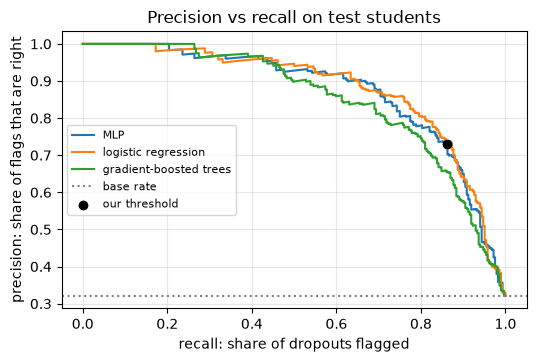

In [19]:
plt.figure(figsize=(6, 3.6))
# One precision-recall curve per model, all on the test students.
for name, p in (("MLP", p_test), ("logistic regression", logreg.predict_proba(X_test)[:, 1]), ("gradient-boosted trees", gbt.predict_proba(X_test)[:, 1])):
    pr, rc, _ = precision_recall_curve(y_test, p)
    plt.plot(rc, pr, label=name)
# Random flagging would have precision equal to the dropout rate at every recall.
plt.axhline(y_test.mean(), color="grey", ls=":", label="base rate")
# Our chosen operating point (the test recall and precision from the previous cell).
plt.scatter([tp / (tp + fn)], [tp / (tp + fp)], color="black", zorder=3, label="our threshold")
plt.xlabel("recall: share of dropouts flagged"); plt.ylabel("precision: share of flags that are right")
plt.title("Precision vs recall on test students"); plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

All three models trace similar curves. The black dot is our operating point. Moving along the curve is a policy decision ("how many conversations can our tutors afford?"), not a technical one.

**How to read the plot:** each curve shows, for one model, the precision (up) you get at each level of recall (across). Further up and to the right is better. The dotted grey line is what random flagging would give.

> **Try it yourself (optional).** Change `target_recall`, for example to reach nine in ten dropouts, or only two in three. Rerun this cell and the plot. Look for: how the threshold moves, how many students are flagged, how many false alarms there are, and where the black dot sits on the curve. Which setting would you recommend to a team with only a few tutors? (Rerun with the original value before Section 9, which uses the flags.)

## 9. Is It Fair?

A system that decides who gets support must work for *every* group of students, not just on average. We check, at our threshold, how many of each group's dropouts are caught:

For each group, the next cell prints its number of test students, its real dropout rate, the share of its students who are flagged, and the share of its dropouts who are caught (the group's own recall). Compare the last figure across groups: that is the fairness question "does the system help struggling students equally?".

In [20]:
# Turn age into three bands: (0, 20], (20, 25], (25, 100].
age_group = pd.cut(test_df["Age at enrollment"], [0, 20, 25, 100], labels=["20 or under", "21-25", "over 25"])
# The groups we check: each value is a column with one entry per test student.
groups = {"Gender (1 = male, 0 = female)": test_df["Gender"], "Scholarship holder": test_df["Scholarship holder"], "Age at enrolment": age_group}
for title, col in groups.items():
    print(title)
    for value in sorted(col.dropna().unique()):
        m = (col == value).to_numpy()                       # True for test students in this group
        drop = (y_test == 1) & m                            # ... who actually dropped out
        # Per group: size, real dropout rate, share flagged, and the group's recall (share of its dropouts flagged).
        print(f"   {str(value):<12} {m.sum():>4} students | dropout rate {y_test[m].mean():.1%} | "
              f"flagged {flag[m].mean():.1%} | dropouts caught {flag[drop].mean():.1%} of {drop.sum()}")

Gender (1 = male, 0 = female)
   0             557 students | dropout rate 23.9% | flagged 27.6% | dropouts caught 82.7% of 133
   1             328 students | dropout rate 46.0% | flagged 55.2% | dropouts caught 89.4% of 151
Scholarship holder
   0             646 students | dropout rate 39.8% | flagged 49.1% | dropouts caught 91.4% of 257
   1             239 students | dropout rate 11.3% | flagged 7.5% | dropouts caught 37.0% of 27
Age at enrolment
   20 or under   492 students | dropout rate 16.9% | flagged 23.0% | dropouts caught 75.9% of 83
   21-25         173 students | dropout rate 41.6% | flagged 45.7% | dropouts caught 87.5% of 72
   over 25       220 students | dropout rate 58.6% | flagged 65.0% | dropouts caught 92.2% of 129


Two findings stand out.
- **Scholarship holders.** The system catches 91.4% of dropouts among students without a scholarship, but only 37.0% among scholarship holders (27 of them in the test set). Scholarship holders rarely drop out (11.3%), so the model has learned that "scholarship" means "safe", and it misses the few who do struggle. Those students would get no warning.
- **Age.** The system catches 75.9% of dropouts among the youngest students (20 or under), and 92.2% among those over 25. Younger students who drop out are less often caught.

Gender shows a smaller gap (82.7% for female students, 89.4% for male).

These are exactly the issues a school would need to discuss before using such a tool. Options include separate thresholds per group, collecting more examples of the under-served groups, or adding human review. Some groups here are small (27 dropouts), so the numbers are uncertain, but the scholarship gap is large enough to take seriously.

## 10. What Drives the Risk?

Which information does the model rely on? A simple, model-agnostic check: shuffle one column across the validation students, breaking its link to the outcome, and see how much ROC-AUC falls. A big drop means the model leans on that column.

This is called **permutation importance**. The next cell shuffles each original column five times and averages the drop, so that one lucky shuffle can't mislead us. It prints the unshuffled validation ROC-AUC, then the eight columns whose shuffling hurts most.

In [69]:
# Permutation importance: works for any model, because it only needs predictions.
cols = nominal + numeric_early                                # the original (unencoded) input columns
base_auc = roc_auc_score(y_val, mlp_proba(mlp, X_val))         # the score with nothing shuffled
rng = np.random.default_rng(0)                                 # seeded, so the shuffles are reproducible
drops = {}
for c in cols:                                               # shuffle one column, see how much the score falls
    losses = []
    for _ in range(5):                                         # repeat 5 times and average, to smooth out luck
        shuffled = val_df[cols].copy()
        # Mix up this column's values between students: it keeps its values but loses its link to the outcome.
        shuffled[c] = rng.permutation(shuffled[c].to_numpy())
        # Re-encode with the same fitted preprocessor, predict, and record how much ROC-AUC fell.
        losses.append(base_auc - roc_auc_score(y_val, mlp_proba(mlp, pre.transform(shuffled).astype(np.float32))))
    drops[c] = np.mean(losses)
# Largest drop first: the columns the model leans on most.
top = pd.Series(drops).sort_values(ascending=False)
print(f"validation ROC-AUC {base_auc:.3f}; drop when each column is shuffled (top 8):")
print(top.head(8).round(4).to_string())

validation ROC-AUC 0.893; drop when each column is shuffled (top 8):
Curricular units 1st sem (approved)    0.1181
Tuition fees up to date                0.0391
Curricular units 1st sem (grade)       0.0379
Curricular units 1st sem (enrolled)    0.0166
Curricular units 1st sem (credited)    0.0063
Course                                 0.0061
Unemployment rate                      0.0055
Gender                                 0.0055


By far the most important signal is **how many first-semester units the student passed** (shuffling it drops ROC-AUC by 0.1181). Then come **whether tuition fees are up to date** (0.0391) and the **first-semester grade** (0.0379). Academic progress and financial strain dominate. That matches what support staff often see, and it points to concrete help: academic tutoring and financial advice.

**What to notice:** most columns barely matter on their own. A small drop does not always mean a column is useless: when two columns carry similar information (units enrolled and units passed, for example), shuffling one leaves the other to do the work, so each can look less important than the pair really is.

## 11. The Application

To use the model, we wrap it in a function that takes a student's record and returns their risk. We save the model, the preprocessor and the threshold to `artifacts/`, so the app can load them without retraining.

"What if" questions show how the risk responds. We take, by a fixed rule, the test student whose risk is closest to 50%, and change one thing at a time:

The next cell saves the column lists, threshold and fitted preprocessor to `artifacts/`, defines `risk(student)`, picks the student, prints their key facts, and then prints the risk after each single change. It also saves this student as the app's default example.

In [70]:
# Save what the app needs besides the weights: the column lists and the chosen threshold ...
with open("artifacts/preprocessor_columns.json", "w") as f:
    json.dump({"nominal": nominal, "numeric": numeric_early, "threshold": threshold}, f)
# ... and the fitted preprocessor itself (joblib saves sklearn objects to a file).
import joblib
joblib.dump(pre, "artifacts/preprocessor.joblib")

def risk(student: dict) -> float:
    """Dropout risk for one student, given their enrolment and first-semester record.

    Input:  student - a dict mapping column name -> value, for every column in nominal + numeric_early.
    Output: a float between 0 and 1, the MLP's estimated probability that this student drops out.
    The record goes through the same fitted preprocessor as the training data, so it is encoded identically.
    """
    # A one-row table, with the columns in the order the preprocessor expects.
    row = pd.DataFrame([student])[nominal + numeric_early]
    # Encode -> (1, n_features) float32 array -> probability; [0] takes the single student's value.
    return float(mlp_proba(mlp, pre.transform(row).astype(np.float32))[0])

k = int(np.argmin(np.abs(p_test - 0.5)))                     # by rule: the test student closest to 50% risk
# Their record as a dict of column -> value (the format risk() expects).
student = test_df.iloc[k][nominal + numeric_early].to_dict()
print(f"test student #{k}: risk {risk(student):.3f} | actually {'dropped out' if y_test[k] else 'did not drop out'}")
print("   their record:", {c: student[c] for c in ["Age at enrollment", "Tuition fees up to date", "Scholarship holder",
                                                  "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (approved)",
                                                  "Curricular units 1st sem (grade)"]})
# "What if" questions: change one thing at a time and recompute the risk.
# 1 - x flips a 0/1 flag; the second change pretends the student passed every unit they enrolled in.
for change in ({"Tuition fees up to date": 1 - student["Tuition fees up to date"]},
               {"Curricular units 1st sem (approved)": student["Curricular units 1st sem (enrolled)"]},
               {"Scholarship holder": 1 - student["Scholarship holder"]}):
    # {**student, **change} is a copy of the record with the changed value(s) overriding the originals.
    print(f"   what if {change}: risk {risk({**student, **change}):.3f}")
# Save this student as the app's default example. NumPy number types aren't JSON-friendly, so convert them to float.
json.dump({k_: (float(v) if isinstance(v, (int, float, np.integer, np.floating)) else v) for k_, v in student.items()},
          open("artifacts/example_student.json", "w"))

test student #852: risk 0.527 | actually dropped out
   their record: {'Age at enrollment': 18, 'Tuition fees up to date': 1, 'Scholarship holder': 0, 'Curricular units 1st sem (enrolled)': 6, 'Curricular units 1st sem (approved)': 5, 'Curricular units 1st sem (grade)': 13.625}
   what if {'Tuition fees up to date': 0}: risk 0.794
   what if {'Curricular units 1st sem (approved)': 6}: risk 0.490
   what if {'Scholarship holder': 1}: risk 0.425


This student, aged 18, passed 5 of 6 first-semester units and had a risk of 0.527. If their tuition fees fell behind, the risk would jump to 0.794. If they had passed all 6 units, it would drop to 0.490, and holding a scholarship would lower it to 0.425. (The model describes patterns in past students, not causes: a scholarship doesn't make a student succeed by itself.)

A support team would use a ranked list. Here are the highest-risk students in the test set:

The next cell adds each test student's risk to the table, sorts from highest risk to lowest, and shows the top eight, with a few key columns and their real outcome (`Target`) for comparison.

In [71]:
# A ranked list for a support team: test students with their risk, a few key facts and their real outcome.
report = test_df.assign(risk=p_test)[["Course", "Age at enrollment", "Tuition fees up to date",
                                      "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)", "risk", "Target"]]
# Highest risk first; show the top 8, rounded to 3 decimal places.
report.sort_values("risk", ascending=False).head(8).round(3)

,Course,Age at enrollment,Tuition fees up to date,Curricular units 1st sem (approved),Curricular units 1st sem (grade),risk,Target
968,9991,49,0,0,0.0,0.998,Dropout
1613,8014,37,0,0,0.0,0.998,Dropout
2847,9773,53,0,0,0.0,0.998,Dropout
3874,9130,41,0,0,0.0,0.997,Dropout
1549,9500,37,0,0,0.0,0.997,Dropout
2696,9254,34,0,0,0.0,0.997,Dropout
4000,9119,34,0,0,0.0,0.997,Dropout
2471,9085,29,0,0,0.0,0.997,Dropout


The top of the list is dominated by students who passed no units in the first semester and whose fees are not up to date, and in this case all of them did drop out.

Finally, the app. `app.py` in this folder builds a small web interface with **Gradio**: sliders and tick-boxes for the most important factors, and a live risk and flag. Run `python app.py` and open the link it prints, or set `LAUNCH_APP = True` below to open it here.

The app loads the files saved in `artifacts/`, so run the notebook above at least once first. Fields that the app does not show are copied from the example student saved above. In class, set `LAUNCH_APP = True` and run the cell; when you are done, stop the cell (or restart the kernel) to close the app.

In [72]:
LAUNCH_APP = True                                             # set True in class to open the app below the cell
if LAUNCH_APP:
    # Importing app.py builds the Gradio interface (loading the files saved above); launch() starts it.
    import app
    app.demo.launch()

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
* To create a public link, set `share=True` in `launch()`.


Created dataset file at: .gradio/flagged/dataset1.csv


> **Try it yourself (optional).** With the app open, start from the example student and change one input at a time: fees, then units passed, then grade. Which single change pushes the risk across the threshold? Then try a combination, such as fees behind *and* a scholarship. Does the app agree with the "what if" results above?

## What We Learned

- **Framing comes first.** We predicted dropout at the end of the first semester, so we used only information available then. Adding second-semester data raised test ROC-AUC from 0.916 to 0.934, a number that could never be delivered in practice.
- **An MLP needs preprocessing.** On validation, encoding and scaling gave 0.893 ROC-AUC, compared with 0.517 for raw columns. These are validation scores; the prepared model scored 0.916 on test.
- **Neural networks aren't automatically best on tables.** Logistic regression (0.921) and gradient-boosted trees (0.900) were as good or nearly so. Measure before choosing.
- **Early stopping** prevented overfitting: the best epoch was 12 of 26. Results were stable across seeds (0.889–0.895 validation ROC-AUC).
- **A threshold turns scores into decisions.** Aiming to catch 4 in 5 dropouts gave a test recall of 0.863 at precision 0.731.
- **Check fairness.** The system caught only 37.0% of dropouts among scholarship holders, against 91.4% for other students.
- **Explain the drivers.** First-semester units passed, fees up to date and grades dominate the risk.
- **Keep the test set for the end.** The preprocessor was fitted on training students; the stopping epoch and the threshold were chosen on validation students; test students were used only to report.
- **A risk score describes patterns, not causes.** "What if" answers show how the model responds, not what would really happen to a student.

| Model | Test ROC-AUC | Test average precision |
|---|---|---|
| Guessing (base rate) | 0.500 | 0.321 |
| Logistic regression | 0.921 | 0.880 |
| MLP (our model) | 0.916 | 0.875 |
| Gradient-boosted trees | 0.900 | 0.852 |
| MLP with 2nd-semester data (not usable in practice) | 0.934 | 0.901 |

**Where next:** Labs 2 and 3 move from tables to images (convolutional networks) and sequences (recurrent networks). The habits from this lab carry over unchanged: frame the moment of prediction, measure baselines, keep a clean test set, and check who the system fails.

## Glossary of Key Terms

- **Average precision:** precision averaged over all thresholds; guessing scores the base rate.
- **Base rate:** the share of positives (here, dropouts) in the data; what random flagging would achieve as precision.
- **Baseline:** a simple model or rule we measure first, so we know whether a complex model really helps.
- **Binary cross-entropy:** the loss for yes/no predictions; it punishes confident wrong probabilities heavily.
- **Dropout (layer):** randomly switching off a share of hidden units during training, to reduce overfitting. Not to be confused with student dropout, the outcome we predict.
- **Early stopping:** watching the validation loss during training and keeping the weights from its best epoch.
- **Epoch / mini-batch:** one full pass over the training data / the small group of examples used for one weight update.
- **Gradient-boosted trees:** many small decision trees built in sequence, each fixing the previous ones' errors.
- **Label (target):** the answer the model learns to predict; here, 1 for dropout and 0 otherwise.
- **Leakage (in time):** using information that would not be available at the moment of prediction.
- **Logit / sigmoid:** the network's raw output score / the function that turns it into a probability between 0 and 1.
- **MLP (multilayer perceptron):** linear layers stacked with non-linear activations (here ReLU) between them.
- **One-hot encoding:** turning a coded category into separate yes/no columns, one per category.
- **Overfitting:** fitting the training examples so closely that performance on new examples gets worse.
- **Permutation importance:** how much a score drops when one input column is shuffled.
- **Precision / recall:** of the flagged students, the share who really drop out / of the students who drop out, the share who are flagged.
- **ROC-AUC:** the chance that a random dropout gets a higher risk score than a random non-dropout.
- **Standard scaling:** shifting and stretching a numeric column to mean 0 and standard deviation 1.
- **Stratified split:** a split that keeps the same share of each class in every part.
- **Threshold:** the risk above which a student is flagged; it turns scores into yes/no decisions.
- **Training / validation / test sets:** data to fit the model / data to make choices / data used only to report results.